# Módulo 1 — Fundamentos, Espacios de Color y Mejoramiento Digital
**PupilTrack — PSIB, ITBA (2do Q 2026) — Grupo 5**

Se trabaja sobre un frame real del **registro A1**, con la luz ya encendida: pupila contraída y reflejo corneal del flash visible, que es el caso que plantea la pregunta del módulo. Para usar otro registro, cambiar solo `VIDEO_PATH` / `FRAME_INDICE`. Si el video no está, el notebook corre sobre una imagen sintética de ojo.

In [1]:
VIDEO_PATH = "../data/A1.mov"   # registro con el que se desarrolla el módulo
FRAME_INDICE = 700              # frame de trabajo (None = el del medio)


## Setup

In [2]:
import sys, os
sys.path.append(os.path.abspath(".."))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pupiltrack import acquisition as acq
from pupiltrack import preprocessing as pp
from pupiltrack import filtering as filt
from pupiltrack import edges_frequency as ef
from pupiltrack import segmentation as seg
from pupiltrack import morphology as morf
from pupiltrack import texture as tex
from pupiltrack import temporal as tmp
from pupiltrack import compression as comp

np.random.seed(0)
pd.set_option("display.width", 200)

def mostrar_varias(imagenes, titulos, cmap="gray", ancho=3.2, filas=1):
    cols = int(np.ceil(len(imagenes) / filas))
    fig, ax = plt.subplots(filas, cols, figsize=(ancho * cols, ancho * filas))
    ax = np.atleast_1d(ax).ravel()
    for a, im, t in zip(ax, imagenes, titulos):
        a.imshow(im if im.ndim == 3 else im, cmap=None if im.ndim == 3 else cmap)
        a.set_title(t, fontsize=9); a.axis("off")
    for a in ax[len(imagenes):]: a.axis("off")
    plt.tight_layout(); plt.show()

def generar_ojo_sintetico(size=300):
    img = np.full((size, size, 3), 230, dtype=np.uint8)
    centro = (size // 2, size // 2)
    cv2.circle(img, centro, 110, (180, 200, 210), -1)
    cv2.circle(img, centro, 70, (90, 60, 40), -1)
    cv2.circle(img, centro, 30, (10, 10, 10), -1)
    cv2.circle(img, (centro[0] + 12, centro[1] - 12), 6, (255, 255, 255), -1)
    return img

## 1.1 — Carga, muestreo y espacios de color
### Frame de trabajo y ROI

Video: ../data/A1.mov | 1494 frames a 59.96 fps | frame de trabajo: 700
ROI del ojo: x=270, y=143, 183x183 px | pupila aprox. 46.0 px


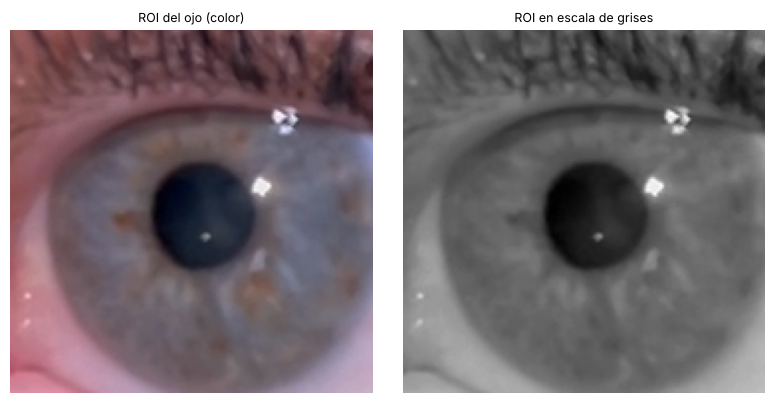

In [3]:
# Frame de trabajo y ROI del ojo (recorte automático alrededor de la pupila)
if VIDEO_PATH and os.path.exists(VIDEO_PATH):
    frames, fps = acq.extraer_frames(VIDEO_PATH)
    i_frame = FRAME_INDICE if FRAME_INDICE is not None else len(frames) // 2
    frame_completo = frames[i_frame]
    (cx, cy), area = tmp.localizar_pupila_inicial(frame_completo)
    d_est = 2 * np.sqrt(area / np.pi)
    gris_completo = cv2.cvtColor(frame_completo, cv2.COLOR_BGR2GRAY)
    lado = int(4 * d_est)
    x0, y0 = int(max(0, cx - lado / 2)), int(max(0, cy - lado / 2))
    frame = frame_completo[y0:y0 + lado, x0:x0 + lado]
    print(f"Video: {VIDEO_PATH} | {len(frames)} frames a {fps:.2f} fps | frame de trabajo: {i_frame}")
    print(f"ROI del ojo: x={x0}, y={y0}, {frame.shape[1]}x{frame.shape[0]} px | pupila aprox. {d_est:.1f} px")
else:
    frame = generar_ojo_sintetico()
    print("No se encontró VIDEO_PATH: se usa una imagen sintética de ojo.")

gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
mostrar_varias([cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), gris], ["ROI del ojo (color)", "ROI en escala de grises"], ancho=4)

### Dimensiones y profundidad

In [4]:
info = pp.info_imagen(frame)
print(f"Profundidad: {8 * frame.dtype.itemsize} bits por canal -> {2 ** (8 * frame.dtype.itemsize)} niveles; {8 * frame.dtype.itemsize * info['canales']} bits por píxel")

Dimensiones: 183x183 | Canales: 3 | Profundidad: uint8
Profundidad: 8 bits por canal -> 256 niveles; 24 bits por píxel


### Resolución espacial: submuestreo al 50 %, 25 % y 5 %
Se reduce la resolución y se vuelve a ampliar al tamaño original (vecino más cercano) para comparar a la misma escala.

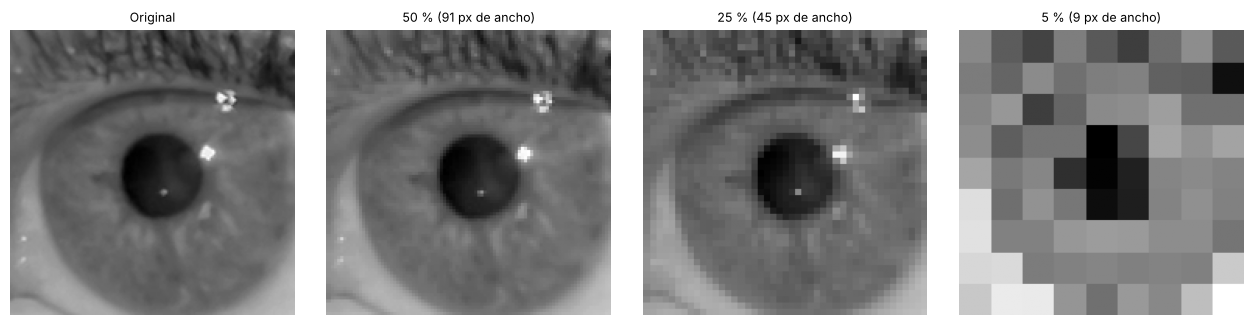

 50 %: PSNR = 34.59 dB | SSIM = 0.945
 25 %: PSNR = 30.69 dB | SSIM = 0.864
  5 %: PSNR = 22.56 dB | SSIM = 0.572


In [5]:
sub = {p: pp.submuestrear(gris, p) for p in (0.5, 0.25, 0.05)}
mostrar_varias([gris] + list(sub.values()), ["Original"] + [f"{int(p * 100)} % ({max(1, int(gris.shape[1] * p))} px de ancho)" for p in sub])
for p, im in sub.items():
    print(f"{int(p * 100):>3} %: PSNR = {filt.psnr(gris, im):5.2f} dB | SSIM = {filt.ssim(gris, im):.3f}")

### Cuantización: 8 → 4 → 2 bits

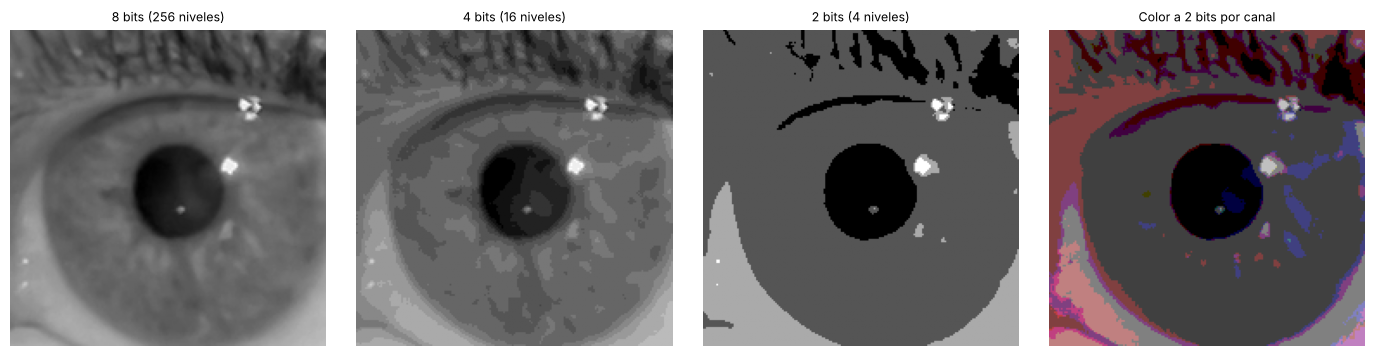

4 bits: 16 niveles distintos | PSNR = 29.24 dB | SSIM = 0.868
2 bits: 4 niveles distintos | PSNR = 16.91 dB | SSIM = 0.594


In [6]:
cuant = {b: pp.cuantizar(gris, b) for b in (4, 2)}
color_2b = (frame // 64) * 64
mostrar_varias([gris, cuant[4], cuant[2], cv2.cvtColor(color_2b, cv2.COLOR_BGR2RGB)],
               ["8 bits (256 niveles)", "4 bits (16 niveles)", "2 bits (4 niveles)", "Color a 2 bits por canal"], ancho=3.5)
for b, im in cuant.items():
    print(f"{b} bits: {len(np.unique(im))} niveles distintos | PSNR = {filt.psnr(gris, im):5.2f} dB | SSIM = {filt.ssim(gris, im):.3f}")

### Espacios de color: RGB y HSV

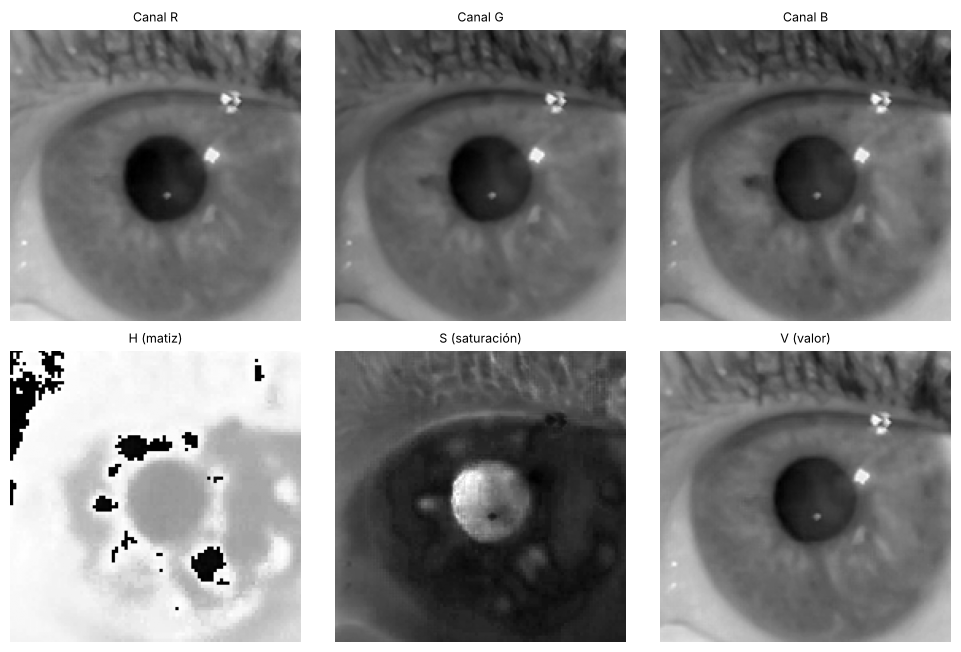

R: media  111.9 | desvío  38.7
G: media   90.1 | desvío  30.3
B: media   99.9 | desvío  33.1
H: media  146.8 | desvío  41.9
S: media   60.4 | desvío  35.1
V: media  115.8 | desvío  36.5


In [7]:
r, g, b = pp.separar_canales_rgb(frame)
h, s, v = pp.rgb_a_hsv(frame)
mostrar_varias([r, g, b, h, s, v], ["Canal R", "Canal G", "Canal B", "H (matiz)", "S (saturación)", "V (valor)"], filas=2, ancho=3.3)
for nombre, c in [("R", r), ("G", g), ("B", b), ("H", h), ("S", s), ("V", v)]:
    print(f"{nombre}: media {c.mean():6.1f} | desvío {c.std():5.1f}")

**Análisis 1.1.**
- **Submuestreo:** al 50 % la pupila y el reflejo se conservan casi sin cambios. Al 25 % el borde pupilar se escalona y desaparecen los detalles finos del estroma del iris. Al 5 % (unos 10 px de ancho) solo se distingue una mancha oscura: el diámetro ya no se puede medir. Las métricas lo reflejan (PSNR y SSIM caen fuerte entre el 25 % y el 5 %).
- **Cuantización:** con 4 bits (16 niveles) aparece *banding* (falsos contornos) en el iris, pero la pupila sigue bien delimitada, porque el contraste pupila/iris es grande. Con 2 bits la imagen queda en 4 niveles: la pupila sigue separada del iris, pero se pierde por completo la textura del iris.
- **Color:** el canal **R** es el más claro y el de mejor contraste pupila/iris en este iris gris-azulado. En **B** el iris es más oscuro y se parece más a la pupila. En HSV, **V** es prácticamente la imagen en gris; **S** resalta la piel y la esclerótica rosada, y **H** es ruidoso en las zonas oscuras, porque el matiz no está definido cuando la saturación es baja (dentro de la pupila).

## 1.2 — Calidad, transformaciones de intensidad y filtrado espacial
### Histograma, brillo (+50) y contraste (×1,5)

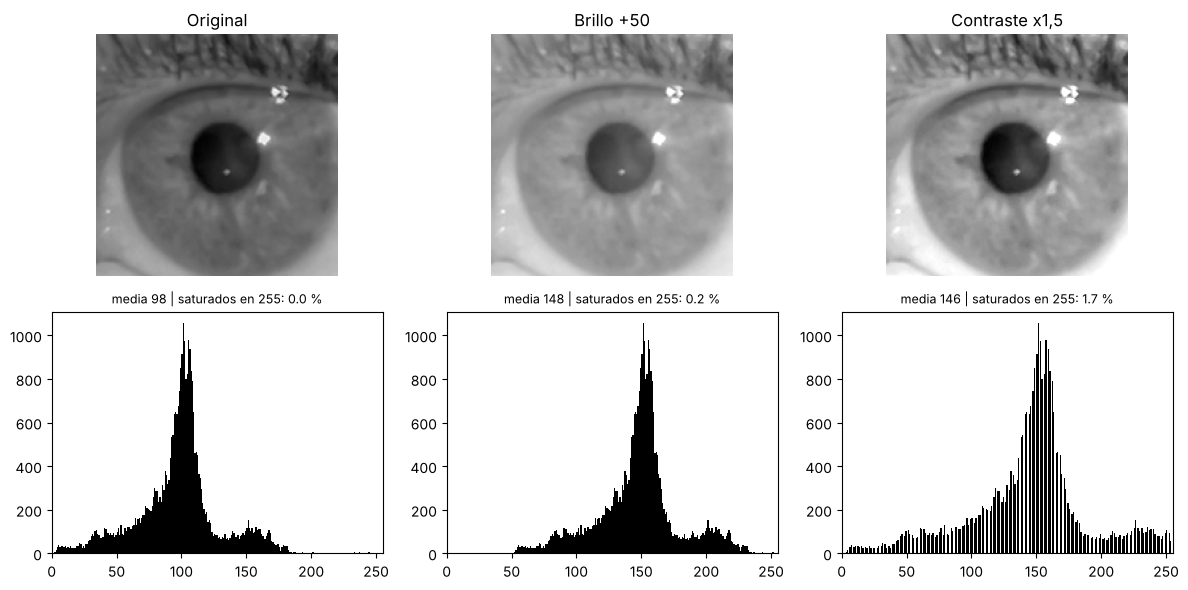

In [8]:
brillo = pp.ajustar_brillo_contraste(gris, brillo=50)
contraste = pp.ajustar_brillo_contraste(gris, contraste=1.5)
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for k, (im, t) in enumerate([(gris, "Original"), (brillo, "Brillo +50"), (contraste, "Contraste x1,5")]):
    ax[0, k].imshow(im, cmap="gray", vmin=0, vmax=255); ax[0, k].set_title(t); ax[0, k].axis("off")
    ax[1, k].hist(im.ravel(), bins=256, range=(0, 256), color="k"); ax[1, k].set_xlim(0, 255)
    sat = 100 * np.mean(im == 255)
    ax[1, k].set_title(f"media {im.mean():.0f} | saturados en 255: {sat:.1f} %", fontsize=9)
plt.tight_layout(); plt.show()

### Escalado lineal por rango de interés [f1, f2] (pupila + iris)

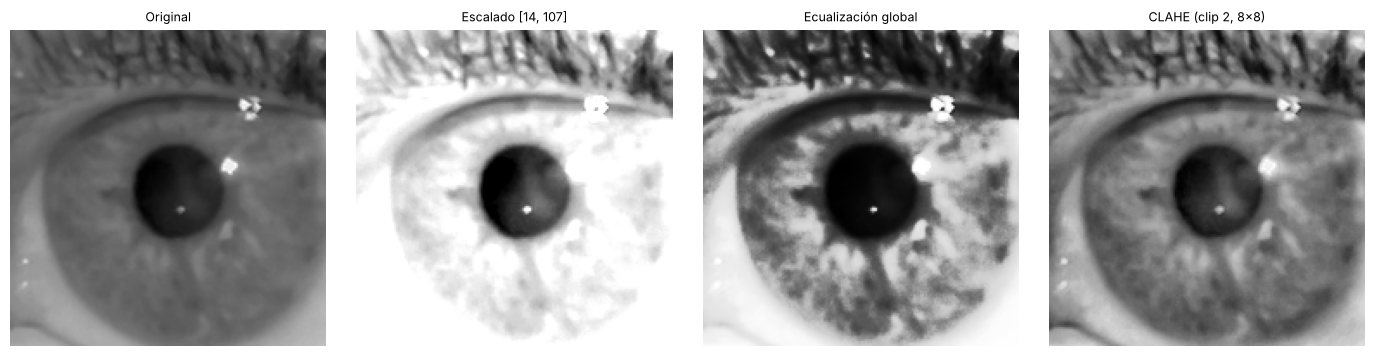

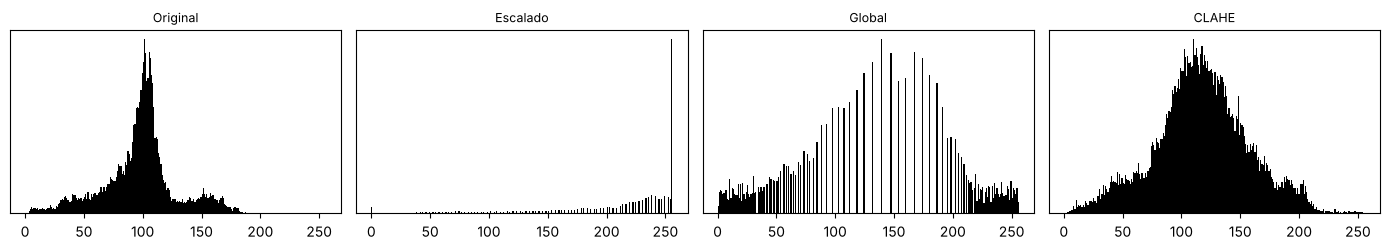

In [9]:
f1, f2 = np.percentile(gris, 1), np.percentile(gris, 70)   # de la pupila al iris
escalada = pp.escalado_por_rango(gris, f1, f2)
global_eq = pp.ecualizar_histograma(gris, "global")
clahe = pp.ecualizar_histograma(gris, "clahe", clip_limit=2.0, tile_size=(8, 8))
mostrar_varias([gris, escalada, global_eq, clahe], ["Original", f"Escalado [{f1:.0f}, {f2:.0f}]", "Ecualización global", "CLAHE (clip 2, 8x8)"], ancho=3.5)
fig, ax = plt.subplots(1, 4, figsize=(14, 2.6))
for a, im, t in zip(ax, [gris, escalada, global_eq, clahe], ["Original", "Escalado", "Global", "CLAHE"]):
    a.hist(im.ravel(), bins=256, range=(0, 256), color="k"); a.set_title(t, fontsize=9); a.set_yticks([])
plt.tight_layout(); plt.show()

**Análisis.**
- **Brillo +50:** el histograma se **desplaza** 50 niveles hacia la derecha sin cambiar de forma. Los píxeles que ya eran claros (esclerótica y reflejo) se **saturan en 255** y se pierde información.
- **Contraste ×1,5:** el histograma se **estira** (hiper-extensión): las diferencias entre niveles crecen, pero todo lo que supera 170 queda saturado en 255.
- **Escalado por rango:** se expande solo el intervalo de la pupila y el iris al rango completo, y gana contraste justo en la zona de interés. Lo que está por encima de f2 (esclerótica y reflejo) se satura, lo cual es aceptable porque no interesa.
- **Ecualización global:** aplana el histograma, pero amplifica también el ruido del interior de la pupila y de la piel, y exagera el reflejo.
- **CLAHE:** realza el contraste local del iris sin sobreamplificar zonas uniformes, porque limita la amplificación con el *clip limit*. Es la que mejor muestra la textura del estroma. Su artefacto típico es un leve halo o "parcheado" entre teselas en las zonas lisas.

### Ruido y filtrado espacial (media, mediana, gaussiano)
Se simulan tres ruidos típicos y se mide cuánto recupera cada filtro (PSNR/SSIM contra la imagen sin ruido).

ruido,Gaussiano (σ=15),Sal y pimienta (2 %),"Speckle (σ=0,2)"
filtro,,,
(sin filtrar),24.680,22.636,21.870
Gaussiano 5x5,34.217,32.531,31.942
Media 5x5,34.220,33.305,32.904
Mediana 5x5,33.735,37.747,31.714


ruido,Gaussiano (σ=15),Sal y pimienta (2 %),"Speckle (σ=0,2)"
filtro,,,
(sin filtrar),0.400,0.552,0.332
Gaussiano 5x5,0.869,0.833,0.803
Media 5x5,0.911,0.882,0.871
Mediana 5x5,0.883,0.973,0.826


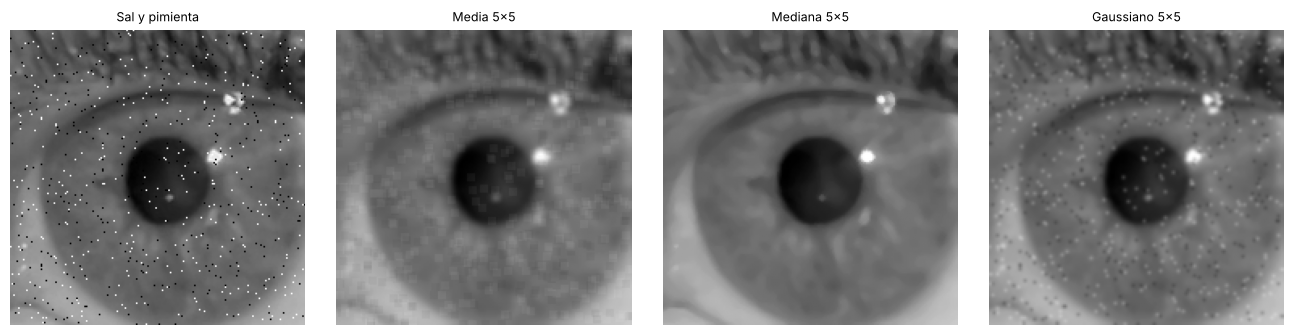

In [10]:
ruidos = {"Gaussiano (σ=15)": filt.agregar_ruido_gaussiano(gris, sigma=15),
          "Sal y pimienta (2 %)": filt.agregar_ruido_sal_pimienta(gris, prob=0.02),
          "Speckle (σ=0,2)": filt.agregar_ruido_speckle(gris, sigma=0.2)}
filtros = {"Media 5x5": lambda im: filt.filtro_media(im, 5),
           "Mediana 5x5": lambda im: filt.filtro_mediana(im, 5),
           "Gaussiano 5x5": lambda im: filt.filtro_gaussiano(im, 5, 1.0)}
filas = []
for nr, ruidosa in ruidos.items():
    filas.append({"ruido": nr, "filtro": "(sin filtrar)", "PSNR_dB": filt.psnr(gris, ruidosa), "SSIM": filt.ssim(gris, ruidosa)})
    for nf, f in filtros.items():
        out = f(ruidosa)
        filas.append({"ruido": nr, "filtro": nf, "PSNR_dB": filt.psnr(gris, out), "SSIM": filt.ssim(gris, out)})
tabla_ruido = pd.DataFrame(filas).round(3)
display(tabla_ruido.pivot(index="filtro", columns="ruido", values="PSNR_dB"))
display(tabla_ruido.pivot(index="filtro", columns="ruido", values="SSIM"))
sp = ruidos["Sal y pimienta (2 %)"]
mostrar_varias([sp] + [f(sp) for f in filtros.values()], ["Sal y pimienta"] + list(filtros), ancho=3.3)

### ¿Qué filtro elimina el reflejo del flash y preserva el borde pupilar?
Se mide, sobre el frame **sin ruido agregado**:
- **Reflejo residual:** brillo máximo que queda en la zona del reflejo corneal (cuanto menor, mejor eliminado).
- **Nitidez del borde pupilar:** gradiente medio sobre el contorno de la pupila, en % del original (cuanto más cerca de 100 %, mejor preservado).
- **Error de diámetro:** diámetro medido (watershed del pipeline) sobre la imagen filtrada, menos el diámetro sobre la original.

,filtro,reflejo_residual_max,nitidez_borde_%,error_diametro_px,PSNR_dB_vs_original
0,Original,251,100.0,0.00,inf
1,Media 5x5,235,83.7,0.30,36.49
2,Mediana 5x5,234,96.8,0.41,37.93
3,Gaussiano 5x5,235,87.2,0.50,38.12
4,Media 9x9,205,63.3,1.02,31.47
5,Mediana 9x9,226,90.9,-0.21,31.91
6,Gaussiano 9x9,218,70.1,0.50,32.96
7,Apertura morfológica (gris) 9x9,152,94.6,-0.41,29.09


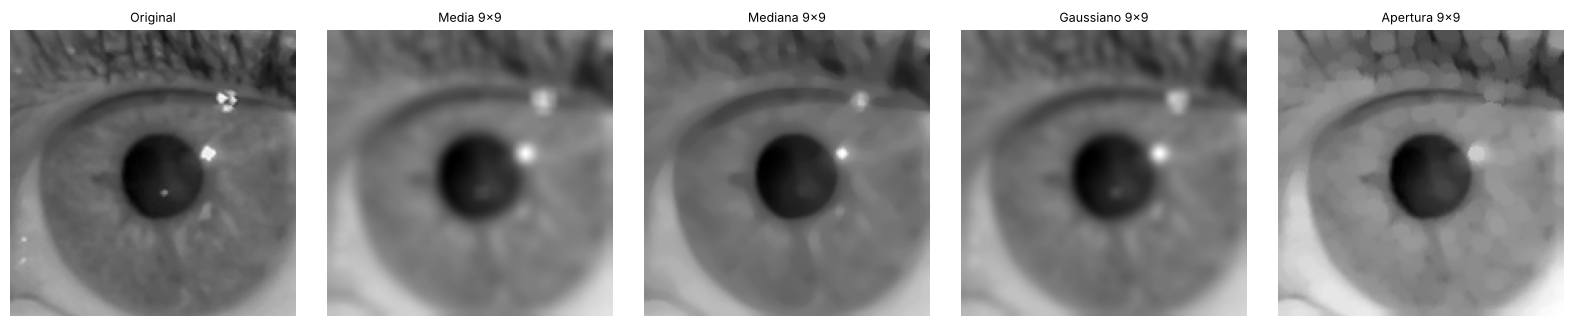

In [11]:
centro_roi = np.array([cx - x0, cy - y0]) if "cx" in dir() else np.array(gris.shape[::-1]) / 2
r_est = d_est / 2 if "d_est" in dir() else 30
mascara_ref = tmp.refinar_borde_watershed(gris, centro_roi, r_est)
borde = cv2.morphologyEx(mascara_ref, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
reflejo = cv2.dilate((gris > np.percentile(gris, 99.7)).astype(np.uint8), np.ones((7, 7), np.uint8)) > 0
grad = lambda im: np.hypot(cv2.Sobel(im.astype(float), cv2.CV_64F, 1, 0), cv2.Sobel(im.astype(float), cv2.CV_64F, 0, 1))
diam = lambda m: 2 * np.sqrt(np.count_nonzero(m) / np.pi) if m is not None else np.nan
g0, d0 = grad(gris)[borde].mean(), diam(mascara_ref)

candidatos = {"Original": gris}
for k in (5, 9):
    candidatos[f"Media {k}x{k}"] = filt.filtro_media(gris, k)
    candidatos[f"Mediana {k}x{k}"] = filt.filtro_mediana(gris, k)
    candidatos[f"Gaussiano {k}x{k}"] = filt.filtro_gaussiano(gris, k, k / 3)
candidatos["Apertura morfológica (gris) 9x9"] = cv2.morphologyEx(gris, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
filas = []
for n, im in candidatos.items():
    m = tmp.refinar_borde_watershed(im, centro_roi, r_est)
    filas.append({"filtro": n, "reflejo_residual_max": int(im[reflejo].max()),
                  "nitidez_borde_%": round(100 * grad(im)[borde].mean() / g0, 1),
                  "error_diametro_px": round(diam(m) - d0, 2),
                  "PSNR_dB_vs_original": round(filt.psnr(gris, im), 2) if n != "Original" else np.inf})
tabla_reflejo = pd.DataFrame(filas)
display(tabla_reflejo)
mostrar_varias([candidatos[k] for k in ["Original", "Media 9x9", "Mediana 9x9", "Gaussiano 9x9", "Apertura morfológica (gris) 9x9"]],
               ["Original", "Media 9x9", "Mediana 9x9", "Gaussiano 9x9", "Apertura 9x9"], ancho=3.2)

**Respuesta — ¿qué filtro preserva mejor el borde pupilar eliminando los destellos del flash?**

- Entre los filtros lineales y la mediana, **la mediana es la que mejor preserva el borde**: con 9×9 conserva el **91 %** de la nitidez del contorno pupilar, contra el 63 % de la media y el 70 % del gaussiano. Además, cambia el diámetro medido en solo −0,2 px. Es un filtro no lineal: reemplaza cada píxel por la mediana del vecindario, así que no "promedia" a través del borde y no lo desplaza.
- Sin embargo, **ningún filtro de 5×5 elimina el reflejo corneal**: el máximo en esa zona sigue en 234–235 (era 251), porque el destello mide unos 6–8 px y ocupa más de la mitad de la ventana. Con 9×9 la mediana lo atenúa poco (226).
- **El que mejor elimina el destello conservando el borde es la apertura morfológica en escala de grises** (erosión + dilatación con un disco de 9×9): baja el reflejo a **152**, al nivel del iris que lo rodea, y conserva el **95 %** de la nitidez del borde, con un error de diámetro de −0,4 px. Elimina las estructuras brillantes más chicas que el elemento estructurante (el reflejo) y deja intactas las grandes (la pupila).
- **En conclusión:** para ruido impulsivo, mediana. Para quitar el reflejo del flash sin afectar el borde, apertura morfológica, o una mediana de tamaño mayor que el reflejo. Los filtros lineales (media y gaussiano) son los peores para este objetivo: borronean el borde y "esparcen" el reflejo en vez de eliminarlo.

**Ruido agregado:** con ruido gaussiano y speckle, la media y el gaussiano dan el mejor PSNR (alrededor de 34 dB y 33 dB). Con sal y pimienta, la **mediana es claramente superior**: 37,7 dB y SSIM de 0,97, contra 33,3 dB y 0,88 de la media, porque descarta los valores extremos en lugar de promediarlos.

## 1.3 — Detección de bordes y dominio frecuencial
### Roberts, Sobel, Prewitt, Laplaciano y Canny (original y filtrada)

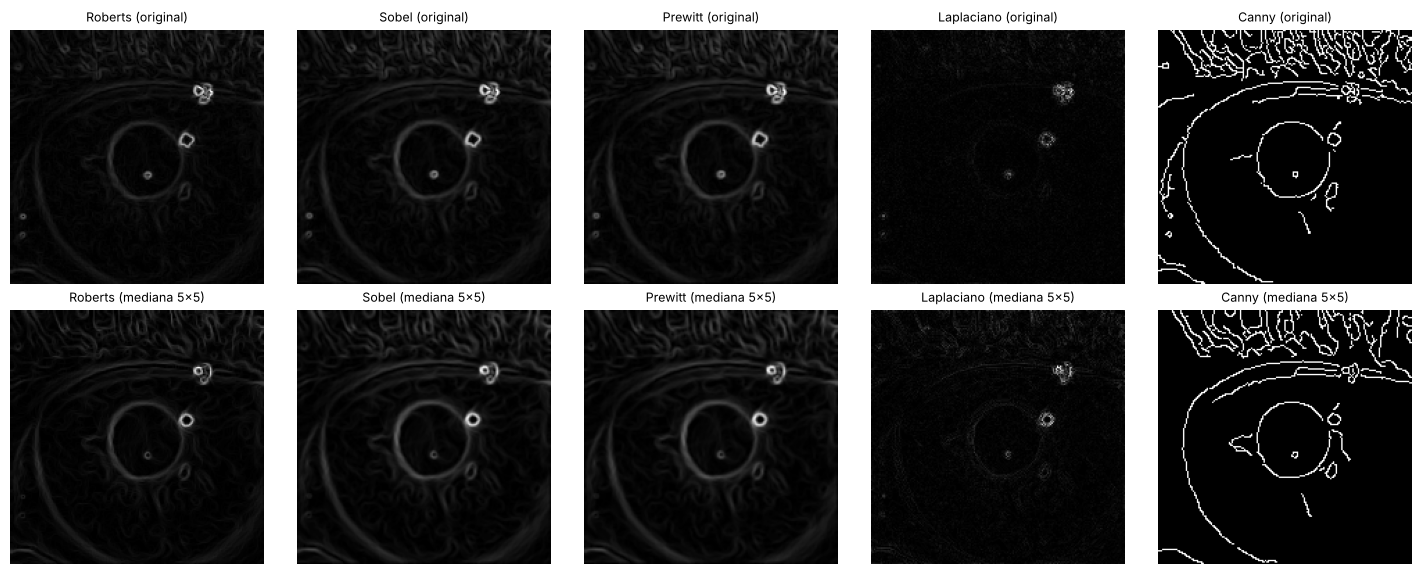

continuidad_contorno_%          pixeles_de_borde_%         
imagen                mediana 5x5 original        mediana 5x5 original
operador                                                              
Canny                       100.0     99.5                5.9      7.3
Laplaciano                   99.8     97.5               10.4     10.0
Prewitt                     100.0    100.0               10.6     10.3
Roberts                     100.0    100.0               10.3     10.4
Sobel                       100.0    100.0               10.4     10.2

In [12]:
filtrada = filt.filtro_mediana(gris, 5)
ops = {"Roberts": ef.bordes_roberts, "Sobel": ef.bordes_sobel, "Prewitt": ef.bordes_prewitt,
       "Laplaciano": ef.bordes_laplaciano, "Canny": lambda im: ef.bordes_canny(im, 30, 90)}

def continuidad(bordes):
    # % del contorno pupilar de referencia que tiene un píxel de borde a <= 2 px.
    # Canny ya es binario; los operadores de gradiente se binarizan con un
    # criterio común: el 10 % de píxeles de mayor respuesta.
    b = bordes > 0 if len(np.unique(bordes)) <= 2 else bordes >= np.percentile(bordes, 90)
    cerca = cv2.dilate(b.astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    contorno = cv2.morphologyEx(mascara_ref, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    return 100 * cerca[contorno].mean(), 100 * b.mean()

imgs, tits, filas = [], [], []
for version, im in [("original", gris), ("mediana 5x5", filtrada)]:
    for n, f in ops.items():
        out = f(im); imgs.append(out); tits.append(f"{n} ({version})")
        cont, dens = continuidad(out)
        filas.append({"operador": n, "imagen": version, "continuidad_contorno_%": round(cont, 1), "pixeles_de_borde_%": round(dens, 1)})
mostrar_varias(imgs, tits, filas=2, ancho=2.9)
tabla_bordes = pd.DataFrame(filas)
display(tabla_bordes.pivot(index="operador", columns="imagen", values=["continuidad_contorno_%", "pixeles_de_borde_%"]))

**Análisis — continuidad del contorno pupilar.**
- En este frame (pupila contraída con luz, borde nítido) **todos los operadores detectan el contorno pupilar completo**: la continuidad está entre el 97,5 % y el 100 %. Las diferencias están en el resto de la imagen.
- **Roberts** (máscara 2×2) es el más sensible al ruido y a la textura fina del iris. **Sobel** y **Prewitt** (3×3) dan un contorno más grueso y estable, y son casi idénticos entre sí. El **Laplaciano** (segunda derivada) responde sobre todo a puntos aislados (los reflejos) y es el más ruidoso, aunque filtrando la imagen el contorno pasa de 97,5 % a 99,8 %.
- **Canny** da el contorno más limpio: bordes de 1 píxel, cerrados alrededor de la pupila, gracias al suavizado previo, la supresión de no-máximos y la histéresis. Filtrar antes con la mediana reduce sus bordes espurios del iris y las pestañas (de 7,3 % a 5,9 % de píxeles de borde) sin cortar el contorno pupilar (99,5 % → 100 %).
- **Conclusión:** para extraer el contorno pupilar conviene **mediana + Canny**.

### Transformada de Fourier 2D: magnitud, fase y reconstrucciones

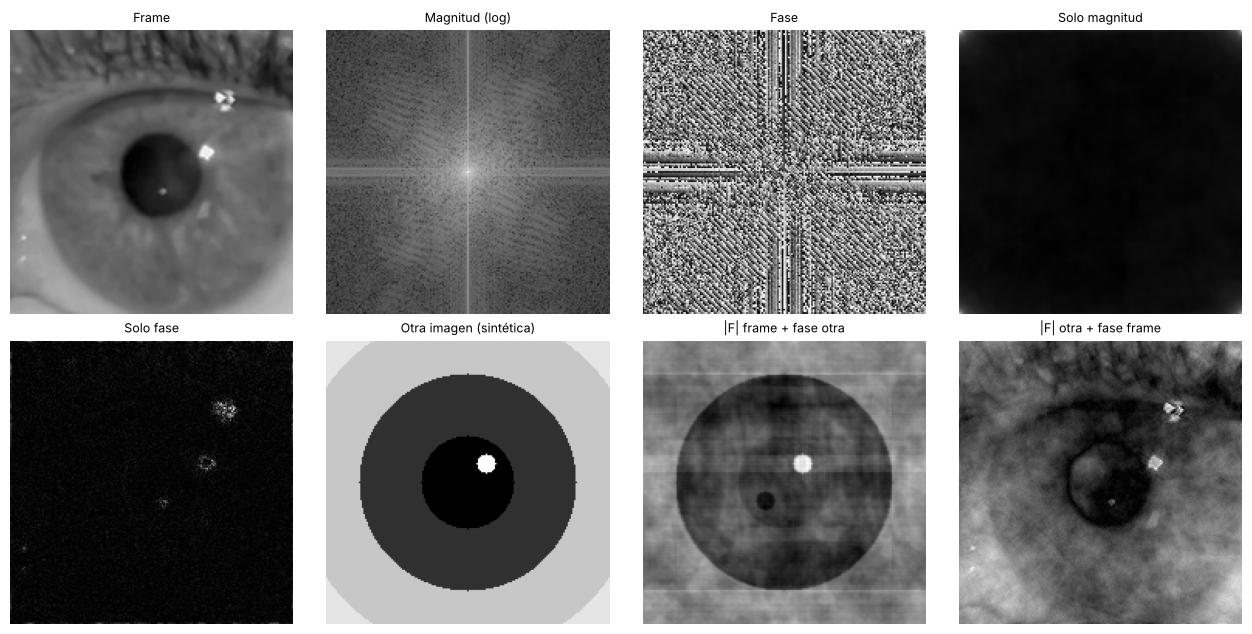

Correlación con el frame -> solo magnitud: 0.277 | solo fase: 0.079
|F| del frame + fase de la otra: corr. con el frame 0.228, con la otra 0.849
|F| de la otra + fase del frame: corr. con el frame 0.790, con la otra 0.465


In [13]:
F = ef.fft2d(gris)
otra = cv2.cvtColor(generar_ojo_sintetico(gris.shape[0]), cv2.COLOR_BGR2GRAY)[:gris.shape[0], :gris.shape[1]]
otra = cv2.resize(otra, gris.shape[::-1])
F2 = ef.fft2d(otra)
solo_mag = ef.reconstruir_solo_magnitud(gris)
solo_fase = ef.reconstruir_solo_fase(gris)
mag_frame_fase_otra = ef.reconstruir_desde_magnitud_fase(np.abs(F), np.angle(F2))
mag_otra_fase_frame = ef.reconstruir_desde_magnitud_fase(np.abs(F2), np.angle(F))
mostrar_varias([gris, ef.espectro_magnitud(F), np.angle(F), solo_mag, solo_fase, otra, mag_frame_fase_otra, mag_otra_fase_frame],
               ["Frame", "Magnitud (log)", "Fase", "Solo magnitud", "Solo fase", "Otra imagen (sintética)",
                "|F| frame + fase otra", "|F| otra + fase frame"], filas=2, ancho=3.2)
corr = lambda a, b: np.corrcoef(a.ravel().astype(float), b.ravel().astype(float))[0, 1]
print(f"Correlación con el frame -> solo magnitud: {corr(gris, solo_mag):.3f} | solo fase: {corr(gris, solo_fase):.3f}")
print(f"|F| del frame + fase de la otra: corr. con el frame {corr(gris, mag_frame_fase_otra):.3f}, con la otra {corr(otra, mag_frame_fase_otra):.3f}")
print(f"|F| de la otra + fase del frame: corr. con el frame {corr(gris, mag_otra_fase_frame):.3f}, con la otra {corr(otra, mag_otra_fase_frame):.3f}")

**¿Qué conserva la información estructural, la magnitud o la fase?** **La fase.**
- La reconstrucción **solo con magnitud** no muestra ninguna estructura reconocible: es una mancha concentrada en el centro.
- **Solo con la fase** se ven las posiciones de los bordes y los detalles (reflejos, contorno), aunque sin los niveles de gris.
- El experimento cruzado lo confirma: con la **magnitud del frame y la fase de la imagen sintética**, el resultado se parece a la imagen sintética (correlación de 0,85 con ella y de solo 0,23 con el frame). A la inversa, con la **magnitud de la sintética y la fase del frame**, se reconoce el ojo real (correlación de 0,79 con el frame).
- La magnitud dice "cuánta energía hay en cada frecuencia"; la fase dice "dónde" están las estructuras. Por eso la forma de la pupila está codificada en la fase.

### Densidad espectral de potencia (PSD) antes y después del filtrado espacial

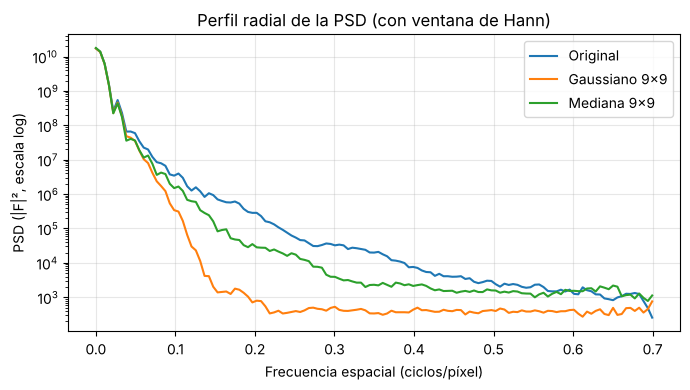

Gaussiano 9x9  : atenuación de la PSD respecto del original a 0,02 / 0,05 / 0,1 / 0,2 / 0,3 c/px = -0.2 / -2.3 / -10.0 / -26.0 / -18.6 dB
Mediana 9x9    : atenuación de la PSD respecto del original a 0,02 / 0,05 / 0,1 / 0,2 / 0,3 c/px = -0.2 / -2.1 / -3.6 / -9.1 / -9.5 dB


In [14]:
versiones = {"Original": gris, "Gaussiano 9x9": filt.filtro_gaussiano(gris, 9, 3), "Mediana 9x9": filt.filtro_mediana(gris, 9)}
fig, ax = plt.subplots(figsize=(7, 4))
for n, im in versiones.items():
    p = ef.psd_radial(im)
    ax.semilogy(np.arange(len(p)) / gris.shape[0], p, label=n)
ax.set_xlabel("Frecuencia espacial (ciclos/píxel)"); ax.set_ylabel("PSD (|F|², escala log)"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Perfil radial de la PSD (con ventana de Hann)"); plt.tight_layout(); plt.show()
p0 = ef.psd_radial(gris)
for n, im in list(versiones.items())[1:]:
    p = ef.psd_radial(im)
    aten = [10 * np.log10(p[int(f * gris.shape[0])] / p0[int(f * gris.shape[0])]) for f in (0.02, 0.05, 0.1, 0.2, 0.3)]
    print(f"{n:15s}: atenuación de la PSD respecto del original a 0,02 / 0,05 / 0,1 / 0,2 / 0,3 c/px = " + " / ".join(f"{a:.1f}" for a in aten) + " dB")

### Filtrado en frecuencia: pasa-bajos y pasa-altos ideales vs. filtrado espacial

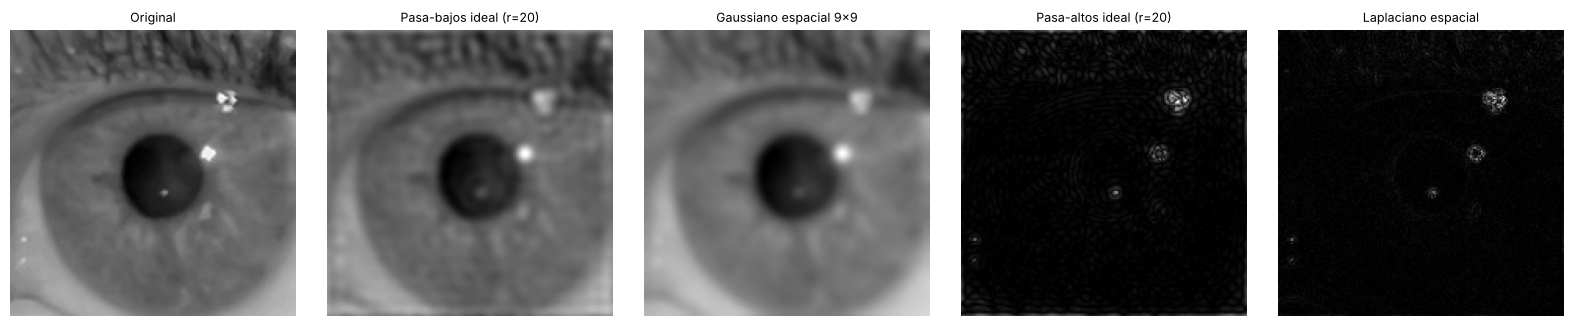

Pasa-bajos ideal: PSNR 32.64 dB | SSIM 0.913
Gaussiano 9x9:    PSNR 32.96 dB | SSIM 0.911
Correlación pasa-altos ideal vs. Laplaciano: 0.596


In [15]:
radio = 20
pb = ef.filtro_frecuencial(gris, "pasabajos", radio)
pa = ef.filtro_frecuencial(gris, "pasaaltos", radio)
gauss = filt.filtro_gaussiano(gris, 9, 3)
lap = ef.bordes_laplaciano(gris)
mostrar_varias([gris, pb, gauss, pa, lap], [f"Original", f"Pasa-bajos ideal (r={radio})", "Gaussiano espacial 9x9",
                                             f"Pasa-altos ideal (r={radio})", "Laplaciano espacial"], ancho=3.2)
print(f"Pasa-bajos ideal: PSNR {filt.psnr(gris, pb):.2f} dB | SSIM {filt.ssim(gris, pb):.3f}")
print(f"Gaussiano 9x9:    PSNR {filt.psnr(gris, gauss):.2f} dB | SSIM {filt.ssim(gris, gauss):.3f}")
print(f"Correlación pasa-altos ideal vs. Laplaciano: {np.corrcoef(pa.ravel().astype(float), lap.ravel().astype(float))[0, 1]:.3f}")

**Análisis — PSD y filtrado en frecuencia.**
- **PSD:** la energía del frame se concentra en frecuencias bajas, que corresponden a las regiones grandes (pupila, iris, piel). El **gaussiano 9×9** atenúa fuerte las frecuencias altas: −10 dB a 0,1 ciclos/px y −26 dB a 0,2 ciclos/px. La **mediana** atenúa bastante menos (−3,6 y −9,1 dB): al ser no lineal, conserva los bordes, que son contenido de alta frecuencia. Eso coincide con la nitidez del borde medida en 1.2.
- **Pasa-bajos ideal (radio 20) vs. gaussiano espacial:** dan una calidad parecida (32,6 dB y SSIM 0,913 contra 33,0 dB y 0,911), pero el pasa-bajos **ideal** genera **ringing** (oscilaciones alrededor de los bordes, por el fenómeno de Gibbs), porque su corte abrupto en frecuencia equivale a convolucionar con una función sinc en el espacio. El gaussiano no tiene ese problema, porque su transformada también es gaussiana.
- **Pasa-altos ideal vs. Laplaciano:** los dos realzan bordes y detalles (correlación de 0,60 entre ellos). El pasa-altos conserva todas las frecuencias por encima del corte, y el Laplaciano pondera más las frecuencias más altas (∝ f²), por eso es más ruidoso.

## Respuestas a las preguntas del Módulo 1

**1. ¿Qué filtro preserva de manera idónea los bordes de la pupila eliminando los destellos o reflejos del flash?**
La **apertura morfológica en escala de grises** con un elemento estructurante mayor que el reflejo (disco de 9×9): elimina el destello (de 251 a 152, el nivel del iris) y conserva el 95 % de la nitidez del borde pupilar. Entre los filtros clásicos, la **mediana** es la mejor: conserva el borde (91 % con 9×9, contra 63 % de la media y 70 % del gaussiano) y es la óptima para el ruido impulsivo. Para eliminar un reflejo de ~7 px necesita una ventana mayor que el reflejo. Los filtros lineales borronean el borde y esparcen el destello.

**2. ¿Cómo se cuantifica la calidad de una imagen al compararla con la original?**
Con métricas de referencia completa:
- **PSNR** = 10·log₁₀(255² / MSE), en dB: mide el error cuadrático medio píxel a píxel. Más alto es mejor; por encima de unos 35–40 dB las diferencias son casi imperceptibles.
- **SSIM** (entre 0 y 1): compara luminancia, contraste y estructura en ventanas locales, por eso se parece más a la percepción visual. 1 significa idéntica.

Están calculadas en este notebook para el submuestreo, la cuantización, cada combinación de ruido y filtro, y los filtros en frecuencia. En los Módulos 2 y 3 también se usan métricas específicas de la tarea (Dice/IoU sobre la máscara y error en el diámetro), porque una buena imagen para el ojo no garantiza una buena segmentación.